# TA-06: Eksplorasi Random Forest untuk Prediksi Niat Beli Pengunjung Toko Online

**Mata Praktikum:** Pembelajaran Mesin | **Modul 06:** Random Forest
**Nama / NIM:** *[isi di sini]*

**Studi kasus:** memprediksi apakah sebuah sesi kunjungan di toko online akan berakhir dengan pembelian (`Revenue = True`) berdasarkan perilaku browsing pengunjung.

**Dataset:** [Online Shoppers Purchasing Intention (Kaggle)](https://www.kaggle.com/datasets/henrysue/online-shoppers-intention). Isinya identik dengan versi UCI (file `online_shoppers_intention.csv`, 12.330 sesi). Letakkan file di folder `data/` atau di folder yang sama dengan notebook ini.

**Alur notebook:**
1. Memuat data dan eksplorasi (termasuk cek ketidakseimbangan kelas)
2. Preprocessing: encoding fitur kategorikal dan split 80/20
3. **Skenario A:** pengaruh jumlah pohon (`n_estimators`)
4. **Skenario B:** pengaruh kedalaman pohon (`max_depth`)
5. Skenario tambahan: `class_weight` untuk menangani ketidakseimbangan
6. Model terbaik: evaluasi lengkap dan Feature Importance (10 fitur teratas)
7. Menyimpan model untuk aplikasi web Flask

In [1]:
import os, time, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, recall_score, precision_score,
                             roc_auc_score, classification_report, confusion_matrix)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.9.1


## 1. Memuat Data dan Eksplorasi

In [2]:
CANDIDATES = ["data/online_shoppers_intention.csv", "online_shoppers_intention.csv"]
DATA_PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError("File CSV tidak ditemukan. Letakkan online_shoppers_intention.csv di folder data/.")

df = pd.read_csv(DATA_PATH)
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [4]:
print("Total nilai hilang:", int(df.isna().sum().sum()))
print("Baris duplikat   :", int(df.duplicated().sum()))
df.describe().T.round(2)

Total nilai hilang: 0
Baris duplikat   : 125


,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.32,3.32,0.0,0.00,1.00,4.00,27.00
Administrative_Duration,12330.0,80.82,176.78,0.0,0.00,7.50,93.26,3398.75
Informational,12330.0,0.50,1.27,0.0,0.00,0.00,0.00,24.00
Informational_Duration,12330.0,34.47,140.75,0.0,0.00,0.00,0.00,2549.38
ProductRelated,12330.0,31.73,44.48,0.0,7.00,18.00,38.00,705.00
ProductRelated_Duration,12330.0,1194.75,1913.67,0.0,184.14,598.94,1464.16,63973.52
BounceRates,12330.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20
ExitRates,12330.0,0.04,0.05,0.0,0.01,0.03,0.05,0.20
PageValues,12330.0,5.89,18.57,0.0,0.00,0.00,0.00,361.76
SpecialDay,12330.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00


### 1.1 Distribusi variabel target (cek ketidakseimbangan kelas)

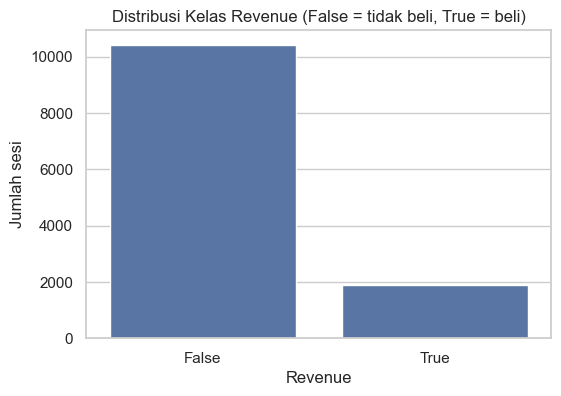

Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False    0.845
True     0.155
Name: proportion, dtype: float64


In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(x="Revenue", data=df)
plt.title("Distribusi Kelas Revenue (False = tidak beli, True = beli)")
plt.xlabel("Revenue"); plt.ylabel("Jumlah sesi")
plt.show()

print(df["Revenue"].value_counts())
print(df["Revenue"].value_counts(normalize=True).round(3))

### 1.2 Hubungan fitur dengan pembelian

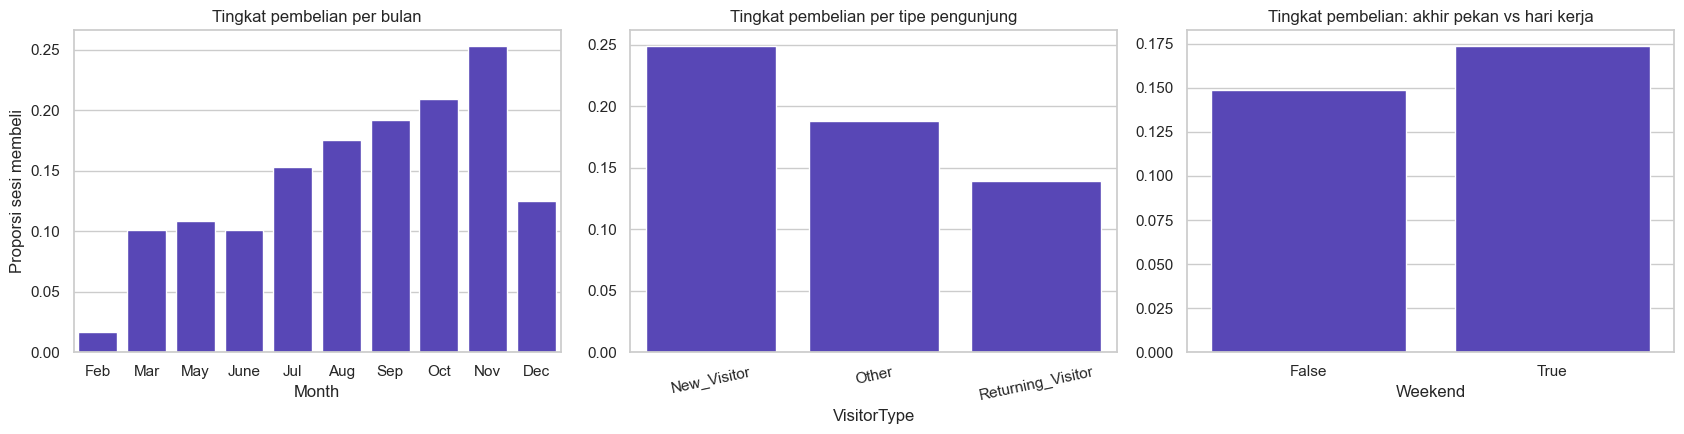

In [6]:
df["Revenue_num"] = df["Revenue"].astype(int)
MONTH_ORDER = [m for m in ["Jan", "Feb", "Mar", "Apr", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
               if m in df["Month"].unique()]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
rate_m = df.groupby("Month")["Revenue_num"].mean().reindex(MONTH_ORDER).reset_index()
sns.barplot(data=rate_m, x="Month", y="Revenue_num", ax=axes[0], color="#4b34c9")
axes[0].set_title("Tingkat pembelian per bulan"); axes[0].set_ylabel("Proporsi sesi membeli")

rate_v = df.groupby("VisitorType")["Revenue_num"].mean().reset_index()
sns.barplot(data=rate_v, x="VisitorType", y="Revenue_num", ax=axes[1], color="#4b34c9")
axes[1].set_title("Tingkat pembelian per tipe pengunjung"); axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=12)

rate_w = df.groupby("Weekend")["Revenue_num"].mean().reset_index()
sns.barplot(data=rate_w, x="Weekend", y="Revenue_num", ax=axes[2], color="#4b34c9")
axes[2].set_title("Tingkat pembelian: akhir pekan vs hari kerja"); axes[2].set_ylabel("")
plt.tight_layout(); plt.show()

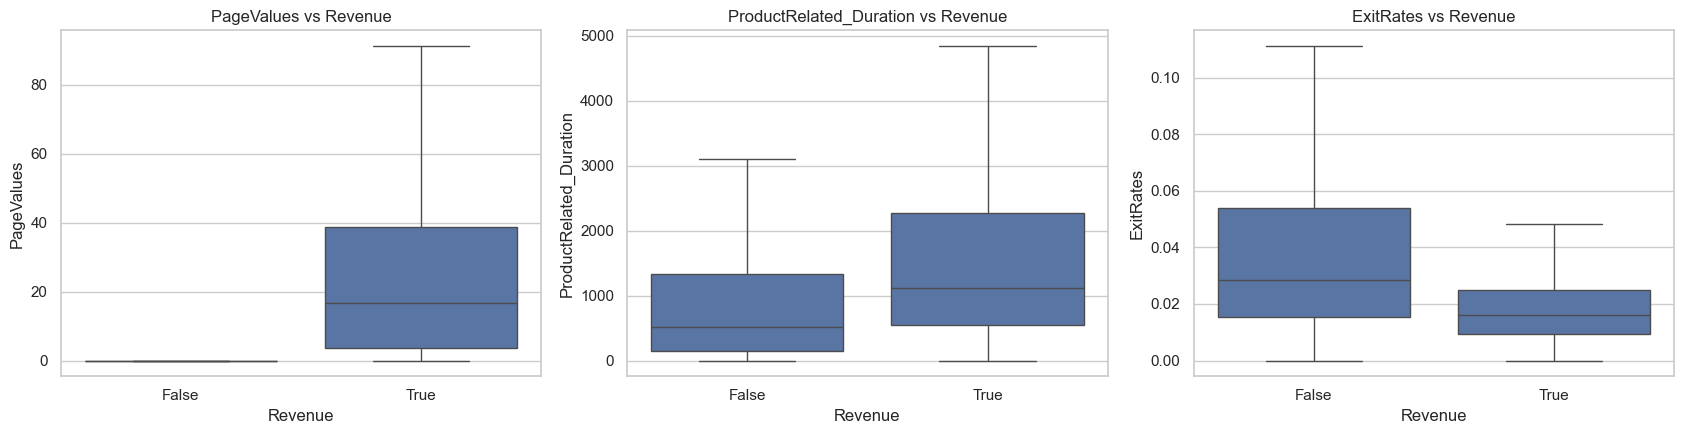

Korelasi fitur numerik dengan Revenue:
PageValues                 0.493
ProductRelated             0.159
ProductRelated_Duration    0.152
Administrative             0.139
Informational              0.095
Administrative_Duration    0.094
Informational_Duration     0.070
Browser                    0.024
TrafficType               -0.005
Region                    -0.012
OperatingSystems          -0.015
SpecialDay                -0.082
BounceRates               -0.151
ExitRates                 -0.207
Name: Revenue_num, dtype: float64


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ["PageValues", "ProductRelated_Duration", "ExitRates"]):
    sns.boxplot(data=df, x="Revenue", y=col, ax=ax, showfliers=False)
    ax.set_title(f"{col} vs Revenue")
plt.tight_layout(); plt.show()

num_corr = (df.select_dtypes(include="number").corr()["Revenue_num"]
            .drop("Revenue_num").sort_values(ascending=False))
print("Korelasi fitur numerik dengan Revenue:")
print(num_corr.round(3))

### 1.3 Temuan eksplorasi
*(Tulis temuan Anda berdasarkan grafik di atas: bagaimana ketidakseimbangan kelasnya, bulan mana yang tingkat pembeliannya tinggi, apakah pengunjung baru dan lama berbeda, dan fitur numerik mana yang tampak paling berkaitan dengan pembelian.)*

## 2. Preprocessing

- **Fitur dibuang:** `OperatingSystems`, `Browser`, `Region`, `TrafficType`. Keempatnya adalah kode angka anonim tanpa arti yang bisa dijelaskan, sehingga sulit diinterpretasikan dan sulit diisi pengguna di aplikasi web.
- **Encoding kategorikal:** `Month` dan `VisitorType` dengan **One-Hot Encoding**. `Weekend` diubah menjadi 0/1.
- **Target:** `Revenue` diubah menjadi 0 (tidak beli) / 1 (beli).
- **Split:** 80% latih, 20% uji dengan `stratify=y` agar proporsi kelas tetap sama.

In [8]:
DROP_COLS = ["OperatingSystems", "Browser", "Region", "TrafficType"]
NUM_COLS = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates",
            "PageValues", "SpecialDay", "Weekend"]
CAT_COLS = ["Month", "VisitorType"]

data = df.drop(columns=DROP_COLS + ["Revenue_num"]).copy()
data["Revenue"] = data["Revenue"].astype(int)
data["Weekend"] = data["Weekend"].astype(int)

X = data[NUM_COLS + CAT_COLS]
y = data["Revenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("Proporsi beli -> latih:", round(y_train.mean(), 3), "| uji:", round(y_test.mean(), 3))


def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("num", "passthrough", NUM_COLS),
            ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
        ],
        sparse_threshold=0,
    )


# Untuk eksperimen (loop), fitur di-encode sekali saja agar cepat
prep_exp = make_preprocessor()
X_train_enc = prep_exp.fit_transform(X_train)
X_test_enc = prep_exp.transform(X_test)
feature_names = [n.split("__", 1)[1] for n in prep_exp.get_feature_names_out()]
print("Jumlah fitur setelah encoding:", len(feature_names))

Data latih: (9864, 13) | Data uji: (2466, 13)
Proporsi beli -> latih: 0.155 | uji: 0.155
Jumlah fitur setelah encoding: 24


## 3. Skenario A: Pengaruh Jumlah Pohon (`n_estimators`)
Model dilatih dengan `n_estimators` = 10, 50, 100, 200, 500 (parameter lain default).

In [9]:
N_LIST = [10, 50, 100, 200, 500]
rows = []
for n in N_LIST:
    t0 = time.time()
    rf = RandomForestClassifier(n_estimators=n, random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(X_train_enc, y_train)
    p_tr, p_te = rf.predict(X_train_enc), rf.predict(X_test_enc)
    rows.append({
        "n_estimators": n,
        "Akurasi latih": accuracy_score(y_train, p_tr),
        "Akurasi uji": accuracy_score(y_test, p_te),
        "F1 kelas Beli (uji)": f1_score(y_test, p_te),
        "Waktu latih (detik)": time.time() - t0,
    })
res_a = pd.DataFrame(rows)
res_a.round(4)

,n_estimators,Akurasi latih,Akurasi uji,F1 kelas Beli (uji),Waktu latih (detik)
0,10,0.9918,0.8974,0.5965,0.2742
1,50,0.9995,0.9011,0.6347,0.3654
2,100,0.9998,0.9027,0.6375,0.7808
3,200,0.9998,0.9019,0.6399,1.3780
4,500,0.9998,0.9027,0.6418,3.4047


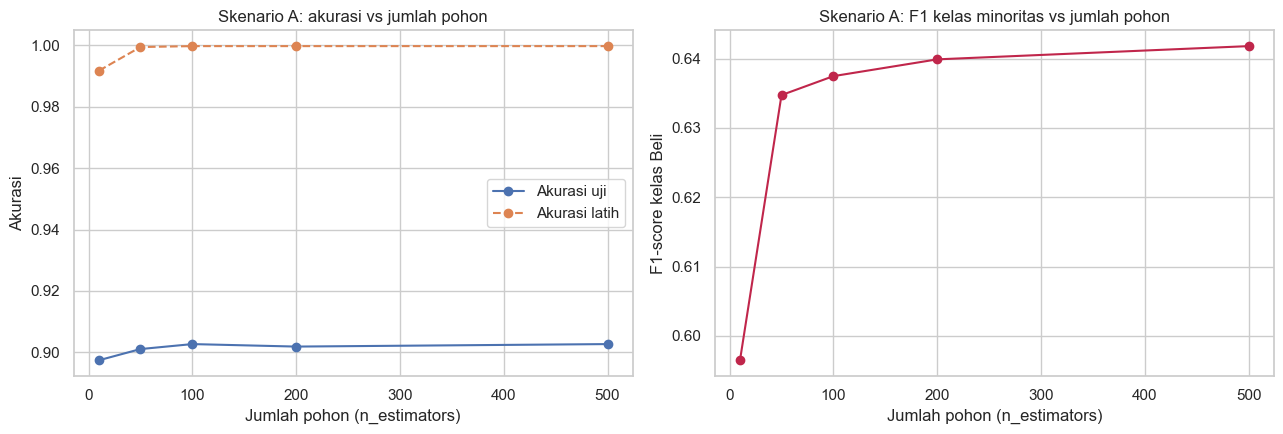

Akurasi uji tertinggi: 0.9027
n_estimators terpilih (paling hemat dalam toleransi 0.005): 50


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(res_a["n_estimators"], res_a["Akurasi uji"], marker="o", label="Akurasi uji")
axes[0].plot(res_a["n_estimators"], res_a["Akurasi latih"], marker="o", linestyle="--", label="Akurasi latih")
axes[0].set_xlabel("Jumlah pohon (n_estimators)"); axes[0].set_ylabel("Akurasi")
axes[0].set_title("Skenario A: akurasi vs jumlah pohon"); axes[0].legend()

axes[1].plot(res_a["n_estimators"], res_a["F1 kelas Beli (uji)"], marker="o", color="#c0264b")
axes[1].set_xlabel("Jumlah pohon (n_estimators)"); axes[1].set_ylabel("F1-score kelas Beli")
axes[1].set_title("Skenario A: F1 kelas minoritas vs jumlah pohon")
plt.tight_layout(); plt.show()

# Aturan pemilihan: jumlah pohon TERKECIL yang akurasi ujinya hanya selisih <= 0.005 (setengah poin persen, dianggap tidak signifikan) dari yang tertinggi
TOL = 0.005
best_n = int(res_a.loc[res_a["Akurasi uji"] >= res_a["Akurasi uji"].max() - TOL, "n_estimators"].min())
print("Akurasi uji tertinggi:", round(res_a["Akurasi uji"].max(), 4))
print("n_estimators terpilih (paling hemat dalam toleransi 0.005):", best_n)

### Analisis Skenario A
*(Jawab dengan melihat tabel dan grafik di atas: apakah menambah pohon terus-menerus meningkatkan akurasi secara signifikan? Mulai dari berapa pohon kurva mendatar? Bagaimana dengan waktu latih? Mengapa Random Forest tidak overfit hanya karena pohonnya bertambah?)*

## 4. Skenario B: Pengaruh Kedalaman Pohon (`max_depth`)
Memakai `n_estimators` terbaik dari Skenario A. Kedalaman yang diuji: `None` (tanpa batas), 3, 5, 10, 20.

In [11]:
DEPTH_LIST = [None, 3, 5, 10, 20]
rows = []
for d in DEPTH_LIST:
    rf = RandomForestClassifier(n_estimators=best_n, max_depth=d, random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(X_train_enc, y_train)
    p_tr, p_te = rf.predict(X_train_enc), rf.predict(X_test_enc)
    rows.append({
        "max_depth": "None" if d is None else d,
        "Kedalaman rata-rata pohon": np.mean([e.get_depth() for e in rf.estimators_]),
        "Akurasi latih": accuracy_score(y_train, p_tr),
        "Akurasi uji": accuracy_score(y_test, p_te),
        "F1 kelas Beli (uji)": f1_score(y_test, p_te),
    })
res_b = pd.DataFrame(rows)
res_b["Selisih (latih - uji)"] = res_b["Akurasi latih"] - res_b["Akurasi uji"]
res_b.round(4)

,max_depth,Kedalaman rata-rata pohon,Akurasi latih,Akurasi uji,F1 kelas Beli (uji),Selisih (latih - uji)
0,None,26.72,0.9995,0.9011,0.6347,0.0984
1,3,3.00,0.8567,0.8536,0.1042,0.0030
2,5,5.00,0.8960,0.8889,0.4945,0.0071
3,10,10.00,0.9427,0.9047,0.6401,0.0380
4,20,20.00,0.9983,0.8962,0.6109,0.1021


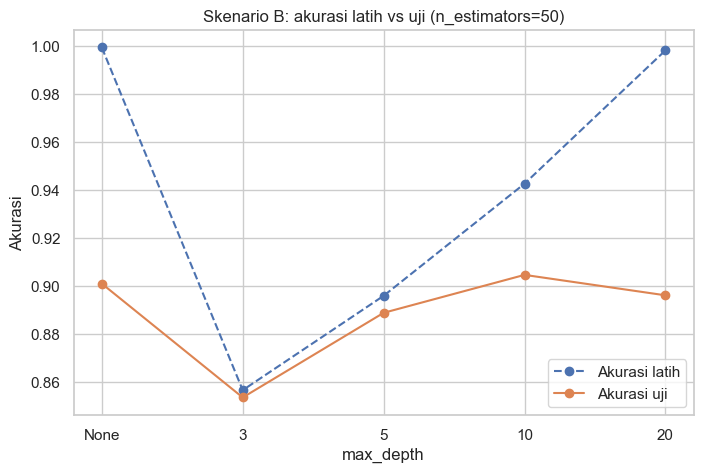

max_depth terpilih: 10


In [12]:
labels = res_b["max_depth"].astype(str).tolist()
x = np.arange(len(labels))
plt.figure(figsize=(8, 5))
plt.plot(x, res_b["Akurasi latih"], marker="o", linestyle="--", label="Akurasi latih")
plt.plot(x, res_b["Akurasi uji"], marker="o", label="Akurasi uji")
plt.xticks(x, labels)
plt.xlabel("max_depth"); plt.ylabel("Akurasi")
plt.title(f"Skenario B: akurasi latih vs uji (n_estimators={best_n})")
plt.legend(); plt.show()

# Aturan pemilihan: dari kandidat yang akurasi ujinya dalam toleransi 0.005 dari tertinggi,
# pilih yang selisih latih-ujinya paling kecil (paling stabil / paling sedikit overfit)
cand = res_b[res_b["Akurasi uji"] >= res_b["Akurasi uji"].max() - TOL]
best_idx = cand["Selisih (latih - uji)"].idxmin()
best_depth = DEPTH_LIST[best_idx]
print("max_depth terpilih:", best_depth)

### Analisis Skenario B
*(Jawab: pada kedalaman berapa akurasi latih mulai jauh melampaui akurasi uji (tanda overfitting)? Apakah `max_depth=None` memberi akurasi uji terbaik? Berapa selisih latih-ujinya? Mengapa batas kedalaman membuat model lebih stabil?)*

## 5. Skenario Tambahan: Menangani Ketidakseimbangan Kelas
Karena hanya sekitar 15% sesi yang berakhir dengan pembelian, akurasi bisa menyesatkan. Bagian ini membandingkan `class_weight=None` dengan `class_weight="balanced"` pada konfigurasi terbaik, dengan fokus pada **recall dan F1 kelas Beli**.

In [13]:
rows = []
for cw in [None, "balanced"]:
    rf = RandomForestClassifier(n_estimators=best_n, max_depth=best_depth, class_weight=cw,
                                random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(X_train_enc, y_train)
    p = rf.predict(X_test_enc)
    rows.append({
        "class_weight": str(cw),
        "Akurasi uji": accuracy_score(y_test, p),
        "Precision (Beli)": precision_score(y_test, p),
        "Recall (Beli)": recall_score(y_test, p),
        "F1 (Beli)": f1_score(y_test, p),
        "AUC": roc_auc_score(y_test, rf.predict_proba(X_test_enc)[:, 1]),
    })
res_c = pd.DataFrame(rows)
res_c.round(4)

,class_weight,Akurasi uji,Precision (Beli),Recall (Beli),F1 (Beli),AUC
0,None,0.9047,0.7712,0.5471,0.6401,0.9222
1,balanced,0.8642,0.5419,0.7958,0.6448,0.9240


*(Bandingkan: apakah `balanced` menaikkan recall kelas Beli, dan berapa harganya pada precision/akurasi? Tentukan pilihan Anda lewat variabel `CLASS_WEIGHT` di sel berikut. Pilih `None` jika akurasi dan stabilitas lebih penting, atau `"balanced"` jika tidak ingin melewatkan calon pembeli.)*

## 6. Model Terbaik: Evaluasi Akhir

In [14]:
CLASS_WEIGHT = None   # ubah ke "balanced" jika itu pilihan Anda berdasarkan bagian 5

final_model = Pipeline([
    ("prep", make_preprocessor()),
    ("clf", RandomForestClassifier(n_estimators=best_n, max_depth=best_depth,
                                   class_weight=CLASS_WEIGHT, random_state=RANDOM_STATE, n_jobs=-1)),
])
final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)[:, 1]

print(f"Konfigurasi akhir: n_estimators={best_n}, max_depth={best_depth}, class_weight={CLASS_WEIGHT}")
print("Akurasi latih:", round(final_model.score(X_train, y_train), 4))
print("Akurasi uji  :", round(accuracy_score(y_test, y_pred), 4))
print("AUC uji      :", round(roc_auc_score(y_test, y_proba), 4))
print()
print(classification_report(y_test, y_pred, target_names=["Tidak Beli", "Beli"]))

Konfigurasi akhir: n_estimators=50, max_depth=10, class_weight=None
Akurasi latih: 0.9427
Akurasi uji  : 0.9047
AUC uji      : 0.9222

              precision    recall  f1-score   support

  Tidak Beli       0.92      0.97      0.95      2084
        Beli       0.77      0.55      0.64       382

    accuracy                           0.90      2466
   macro avg       0.85      0.76      0.79      2466
weighted avg       0.90      0.90      0.90      2466



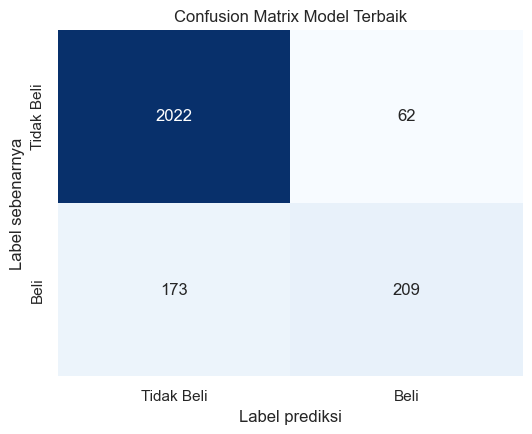

In [15]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Tidak Beli", "Beli"], yticklabels=["Tidak Beli", "Beli"])
plt.xlabel("Label prediksi"); plt.ylabel("Label sebenarnya")
plt.title("Confusion Matrix Model Terbaik")
plt.show()

## 7. Feature Importance (10 Fitur Teratas)

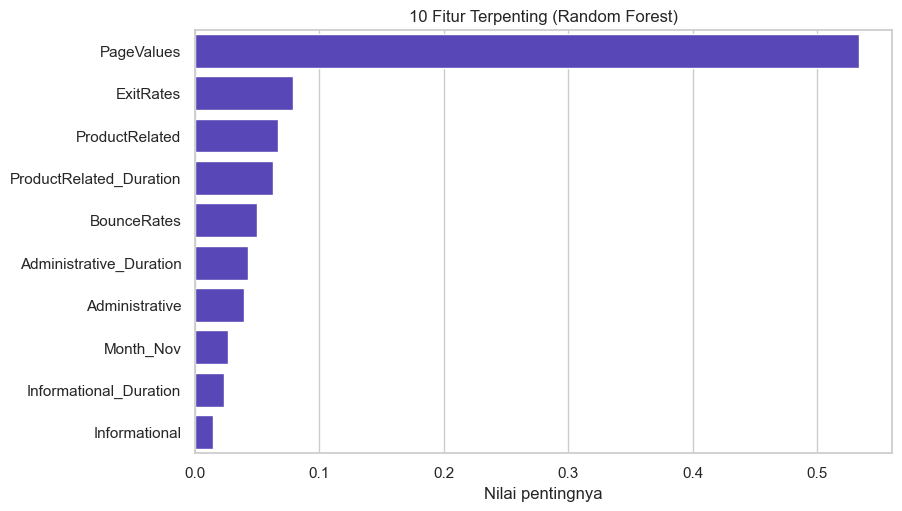

,Fitur,Pentingnya
0,PageValues,0.5335
1,ExitRates,0.0794
2,ProductRelated,0.0674
3,ProductRelated_Duration,0.0626
4,BounceRates,0.0500
5,Administrative_Duration,0.0428
6,Administrative,0.0394
7,Month_Nov,0.0268
8,Informational_Duration,0.0237
9,Informational,0.0150


In [16]:
rf_final = final_model.named_steps["clf"]
names = [n.split("__", 1)[1] for n in final_model.named_steps["prep"].get_feature_names_out()]
imp = (pd.DataFrame({"Fitur": names, "Pentingnya": rf_final.feature_importances_})
       .sort_values("Pentingnya", ascending=False).reset_index(drop=True))

plt.figure(figsize=(9, 5.5))
sns.barplot(data=imp.head(10), x="Pentingnya", y="Fitur", color="#4b34c9")
plt.title("10 Fitur Terpenting (Random Forest)")
plt.xlabel("Nilai pentingnya"); plt.ylabel("")
plt.show()
imp.head(10).round(4)

In [17]:
# Versi ringkas: gabungkan kolom hasil One-Hot kembali ke fitur aslinya
def original_name(n):
    for c in CAT_COLS:
        if n.startswith(c + "_"):
            return c
    return n

imp_agg = (imp.assign(Asli=imp["Fitur"].map(original_name))
           .groupby("Asli")["Pentingnya"].sum().sort_values(ascending=False))
imp_agg.round(4)

Asli
PageValues                 0.5335
ExitRates                  0.0794
ProductRelated             0.0674
ProductRelated_Duration    0.0626
Month                      0.0569
BounceRates                0.0500
Administrative_Duration    0.0428
Administrative             0.0394
Informational_Duration     0.0237
VisitorType                0.0198
Informational              0.0150
Weekend                    0.0065
SpecialDay                 0.0029
Name: Pentingnya, dtype: float64

### Interpretasi Feature Importance
*(Jelaskan fitur mana yang paling berpengaruh dan **apakah sesuai intuisi bisnis e-commerce**. Contoh bahan pembahasan: apa arti `PageValues` (nilai rata-rata halaman yang dikunjungi sebelum transaksi), mengapa `ExitRates` dan `BounceRates` berkaitan negatif dengan pembelian, dan apa peran durasi di halaman produk.)*

### Wawasan Bisnis yang Dapat Ditindaklanjuti
*(Terjemahkan hasil menjadi 2-3 rekomendasi konkret untuk pengelola toko, misalnya halaman atau perilaku mana yang perlu dioptimalkan, kapan kampanye paling efektif, dan bagaimana memperlakukan pengunjung baru vs pengunjung lama.)*

## 8. Kesimpulan Konfigurasi Terbaik

In [18]:
print("Konfigurasi terbaik dan stabil untuk dataset ini:")
print(f"  n_estimators = {best_n}")
print(f"  max_depth    = {best_depth}")
print(f"  class_weight = {CLASS_WEIGHT}")
print(f"  Akurasi uji  = {accuracy_score(y_test, y_pred):.4f} | F1 kelas Beli = {f1_score(y_test, y_pred):.4f}")

Konfigurasi terbaik dan stabil untuk dataset ini:
  n_estimators = 50
  max_depth    = 10
  class_weight = None
  Akurasi uji  = 0.9047 | F1 kelas Beli = 0.6401


*(Tulis kesimpulan Anda dengan kata-kata sendiri: konfigurasi mana yang terbaik, kenapa, dan apa batasan model ini.)*

## 9. Menyimpan Model untuk Aplikasi Web
Yang disimpan adalah seluruh pipeline (encoding + Random Forest) dengan kompresi, supaya ukurannya kecil dan muat di GitHub (batas 100 MB per file).

In [19]:
os.makedirs("model", exist_ok=True)
MODEL_PATH = "model/shoppers_random_forest.joblib"

final_model.named_steps["clf"].n_jobs = None   # prediksi di server tidak perlu multi-proses
joblib.dump(final_model, MODEL_PATH, compress=3)
size_mb = os.path.getsize(MODEL_PATH) / 1024 / 1024
print(f"Model tersimpan: {MODEL_PATH} ({size_mb:.1f} MB)")
if size_mb > 90:
    print("PERINGATAN: ukuran mendekati batas 100 MB GitHub. Pertimbangkan n_estimators atau max_depth yang lebih kecil.")

loaded = joblib.load(MODEL_PATH)
contoh = pd.DataFrame([{
    "Administrative": 2, "Administrative_Duration": 80.0, "Informational": 0, "Informational_Duration": 0.0,
    "ProductRelated": 30, "ProductRelated_Duration": 1200.0, "BounceRates": 0.01, "ExitRates": 0.02,
    "PageValues": 18.0, "SpecialDay": 0.0, "Weekend": 0, "Month": "Nov", "VisitorType": "Returning_Visitor",
}])
print("Peluang membeli untuk sesi contoh:", round(float(loaded.predict_proba(contoh)[0, 1]), 3))

Model tersimpan: model/shoppers_random_forest.joblib (0.6 MB)
Peluang membeli untuk sesi contoh: 0.494


In [20]:
# Versi library saat model dilatih. Samakan di requirements.txt agar model dapat dimuat saat deployment.
import pandas, numpy
reqs = f"""flask>=3.0
gunicorn>=21.2
pandas=={pandas.__version__}
numpy=={numpy.__version__}
scikit-learn=={sklearn.__version__}
joblib=={joblib.__version__}
"""
print(reqs)
with open("requirements.txt", "w") as f:
    f.write(reqs)

flask>=3.0
gunicorn>=21.2
pandas==2.1.4
numpy==1.26.4
scikit-learn==1.9.1
joblib==1.6.0

